# Percobaan Evaluasi Precision@K

Notebook ini menguji `src/evaluation.py` dengan **data dummy**. Tujuannya:
- Menghitung rata-rata Precision@K untuk KNN fuzzy (α = 0,5) dan KNN biasa (α = 1).
- Melihat pengaruh α lewat `alpha_sweep`, lalu menggambar grafik untuk BAB IV.

**Catatan penting.** Pada data dummy, matriks keanggotaan `U` dibuat acak, bukan hasil FCM sungguhan. Karena itu metode fuzzy **belum tentu lebih baik** daripada KNN biasa. Perbandingan yang bermakna baru bisa dilakukan setelah data bersih (Anggota 1) dan matriks U (Anggota 2) tersedia. Jika hasilnya belum unggul, itu temuan yang sah, bukan kesalahan kode.


## 1. Siapkan path dan data dummy

Cell di bawah menambahkan folder proyek (satu tingkat di atas `notebooks/`) ke `sys.path`, supaya `from src.evaluation import ...` bisa dijalankan dari notebook ini.


In [1]:
import os
import sys

root = os.path.abspath('..')
sys.path.insert(0, root)

import numpy as np
import matplotlib.pyplot as plt

from src.evaluation import alpha_sweep, compare_methods, mean_precision_at_k

rng = np.random.default_rng(42)
X = rng.random((30, 4))          # 30 film, 4 fitur
U = rng.random((30, 3))
U = U / U.sum(axis=1, keepdims=True)  # keanggotaan 3 cluster, tiap baris jumlahnya 1

# Matriks genre one-hot/multi-hot: 5 genre, tiap film punya 1–3 genre acak.
G = np.zeros((30, 5), dtype=float)
for i in range(30):
    n_genre = int(rng.integers(1, 4))
    G[i, rng.choice(5, size=n_genre, replace=False)] = 1.0

print("Folder proyek:", root)
print("Bentuk X:", X.shape)
print("Bentuk U:", U.shape)
print("Bentuk G:", G.shape)
print("Jumlah genre per film:", G.sum(axis=1).astype(int))


Folder proyek: d:\Projek\rekomendasi-film-fcm
Bentuk X: (30, 4)
Bentuk U: (30, 3)
Bentuk G: (30, 5)
Jumlah genre per film: [3 3 3 1 3 1 2 2 1 3 1 1 1 3 3 1 2 3 1 1 3 1 2 3 3 1 1 3 1 2]


## 2. Bandingkan KNN fuzzy dengan KNN biasa

`compare_methods` memakai himpunan kueri yang sama untuk kedua metode. `selisih` = P@K fuzzy − P@K baseline. Nilai positif berarti fuzzy lebih baik.


In [2]:
k = 5
alpha = 0.5

hasil = compare_methods(X, U, G, k=k, alpha=alpha)
print("k =", hasil["k"], "  α fuzzy =", hasil["alpha"])
print("Precision@K fuzzy     :", round(hasil["precision_fuzzy"], 4))
print("Precision@K baseline  :", round(hasil["precision_baseline"], 4), "  (α = 1)")
print("Selisih (fuzzy − baseline):", round(hasil["selisih"], 4))

# Pemeriksaan: baseline harus sama dengan rata-rata P@K pada α = 1.
p_cek = mean_precision_at_k(X, U, G, k=k, alpha=1.0)
print()
print("Cek baseline vs mean_precision_at_k(α=1):", round(p_cek, 4),
      "  cocok?", np.isclose(hasil["precision_baseline"], p_cek))


k = 5   α fuzzy = 0.5
Precision@K fuzzy     : 0.58
Precision@K baseline  : 0.5933   (α = 1)
Selisih (fuzzy − baseline): -0.0133

Cek baseline vs mean_precision_at_k(α=1): 0.5933   cocok? True


## 3. Pengaruh α terhadap Precision@K

Nilai α diuji dari 0 (hanya keanggotaan) sampai 1 (hanya fitur). Grafik ini nanti bisa dipakai di BAB IV, dengan data asli sebagai pengganti data dummy.


α      Precision@K
0.0    0.5467
0.25   0.5333
0.5    0.5800
0.75   0.5800
1.0    0.5933


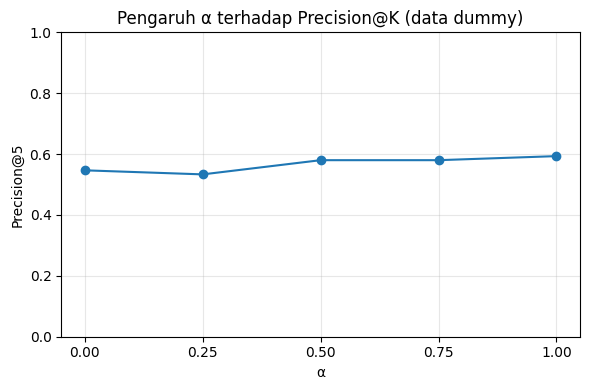

In [3]:
alphas = (0.0, 0.25, 0.5, 0.75, 1.0)
sweep = alpha_sweep(X, U, G, alphas=alphas, k=k)

print("α      Precision@K")
for baris in sweep:
    print(f"{baris['alpha']:<6} {baris['precision']:.4f}")

daftar_alpha = [baris["alpha"] for baris in sweep]
daftar_p = [baris["precision"] for baris in sweep]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(daftar_alpha, daftar_p, marker="o")
ax.set_xlabel("α")
ax.set_ylabel(f"Precision@{k}")
ax.set_title("Pengaruh α terhadap Precision@K (data dummy)")
ax.set_xticks(daftar_alpha)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## 4. Cara membaca hasil ini

Jika kurva di atas tidak memuncak di α = 0,5, itu wajar pada data acak. Yang perlu dicek sekarang hanyalah: kode berjalan, nilai P@K berada di antara 0 dan 1, dan hasil α = 1 sama dengan baseline. Setelah `X`, `U`, dan `G` asli tersedia, notebook yang sama cukup dijalankan ulang untuk mendapat angka yang masuk laporan.
